# Lab 2. Зниження розмірності, кластеризація та класифікація текстів

## ФБ-61мп Тютюннікова Віолета

## 1. Зниження розмірності та візуалізація даних

### Імпорт бібліотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, silhouette_score,
                             adjusted_rand_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
PURPLE = "#8e7cc3"
LIGHT = "#c9bfe6"
soft = sns.light_palette(PURPLE, as_cmap=True)
DARK_TEXT = {"color": "#2d2440"}
CLASS_COLORS = {"Non-Tor": "#5e4fa2", "NonVPN": "#f28e2b", "Tor": "#d62728", "VPN": "#59a14f"}

### Підготовка даних

Повторюємо передобробку з Lab 1: видаляємо мітку іншої задачі Label.1, дублікати та константні ознаки, кодуємо Protocol через One-Hot і беремо вибірку 30 000 потоків зі збереженням пропорцій класів.

In [2]:
df = pd.read_parquet("cicdarknet2020.parquet")
target = "Label"

df = df.drop(columns=["Label.1"])
df = df.drop_duplicates()
const_cols = [c for c in df.columns if c != target and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

ohe = OneHotEncoder(sparse_output=False)
protocol_encoded = ohe.fit_transform(df[["Protocol"]])
protocol_df = pd.DataFrame(protocol_encoded,
                           columns=ohe.get_feature_names_out(["Protocol"]),
                           index=df.index)
df = pd.concat([df.drop(columns=["Protocol"]), protocol_df], axis=1)

df_s, _ = train_test_split(df, train_size=30000, stratify=df[target], random_state=RANDOM_STATE)
print("Розмір вибірки:", df_s.shape)
print(df_s[target].value_counts())

Розмір вибірки: (30000, 65)
Label
Non-Tor    19215
NonVPN      5387
VPN         5046
Tor          352
Name: count, dtype: int64


### Розділяємо на train/test та масштабуємо

Для kNN, PCA, t-SNE та K-Means ознаки мають бути в одному масштабі, тому застосовуємо StandardScaler, навчений лише на train.

In [3]:
X = df_s.drop(columns=target)
y = df_s[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)
print("Ознак до PCA:", scaled_X_train.shape[1])

Ознак до PCA: 64


### Класифікація до та після PCA

Беремо найкращу модель з Lab 1, а саме Random Forest. Спочатку навчаємо її на всіх масштабованих ознаках, потім застосовуємо PCA(n_components=0.95), тобто залишаємо стільки компонент, щоб зберегти 95% дисперсії, і навчаємо ту саму модель на стиснених даних. Порівнюємо accuracy, macro F1, кількість ознак і час навчання.

In [4]:
def fit_eval(X_tr, X_te, label):
    model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    t0 = time.perf_counter()
    model.fit(X_tr, y_train)
    t1 = time.perf_counter()
    pred = model.predict(X_te)
    return {"Модель": label,
            "Ознак": X_tr.shape[1],
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro"),
            "Час навчання, с": round(t1 - t0, 2)}

res_no_pca = fit_eval(scaled_X_train, scaled_X_test, "Без PCA")

pca = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(scaled_X_train)
pca_X_train = pca.transform(scaled_X_train)
pca_X_test = pca.transform(scaled_X_test)
print(f"PCA залишив {pca.n_components_} компонент із {scaled_X_train.shape[1]}, "
      f"збережено {pca.explained_variance_ratio_.sum():.3f} дисперсії")

res_pca = fit_eval(pca_X_train, pca_X_test, "З PCA (0.95)")

compare = pd.DataFrame([res_no_pca, res_pca])
compare.round(4)

PCA залишив 26 компонент із 64, збережено 0.950 дисперсії


,Модель,Ознак,Accuracy,Macro F1,"Час навчання, с"
0,Без PCA,64,0.9723,0.9402,0.74
1,З PCA (0.95),26,0.9462,0.8920,2.87


### Графік накопиченої дисперсії

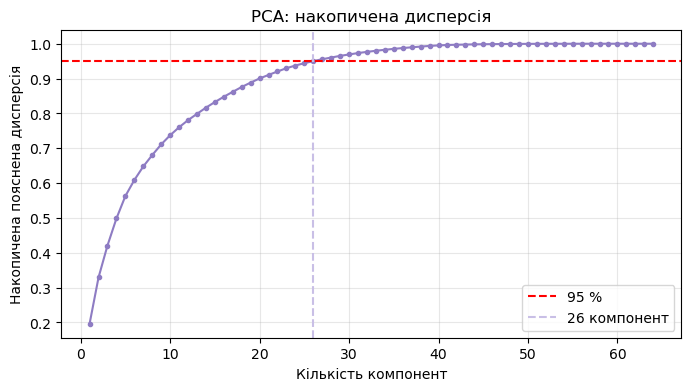

In [5]:
pca_full = PCA(random_state=RANDOM_STATE).fit(scaled_X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o", color=PURPLE, markersize=3)
plt.axhline(0.95, color="red", linestyle="--", label="95 %")
plt.axvline(pca.n_components_, color=LIGHT, linestyle="--", label=f"{pca.n_components_} компонент")
plt.xlabel("Кількість компонент")
plt.ylabel("Накопичена пояснена дисперсія")
plt.title("PCA: накопичена дисперсія")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

PCA зберіг 95% дисперсії, залишивши 26 компонент замість 64. Якість класифікації Random Forest при цьому знизилась: accuracy з 0.972 до 0.946, а macro F1 з 0.940 до 0.892. Macro F1 впала сильніше, бо вона чутлива до малих класів Tor і VPN, а саме їх розрізняють дрібні деталі, які потрапили у відкинуті 5% дисперсії. Час навчання не зменшився, а зріс у кілька разів (у цьому запуску з 0.74 до 2.87 с). Причина в тому, що дерево шукає пороги по кожній ознаці, а компоненти PCA це щільні неперервні числа з великою кількістю унікальних значень, тоді як багато початкових ознак мали мало різних значень і ділились швидко. Крім того, PCA змішує ознаки, і межі класів, які були паралельні осям, стають похилими, що деревам незручно. Отже, для цього датасету PCA корисний для стиснення й візуалізації, але не для покращення чи прискорення Random Forest.

### t-SNE: візуалізація у 2D

t-SNE на 30 000 точок рахувався б дуже довго, тому беремо випадкову підвибірку 4000 потоків. Ініціалізуємо t-SNE через PCA для стабільності.

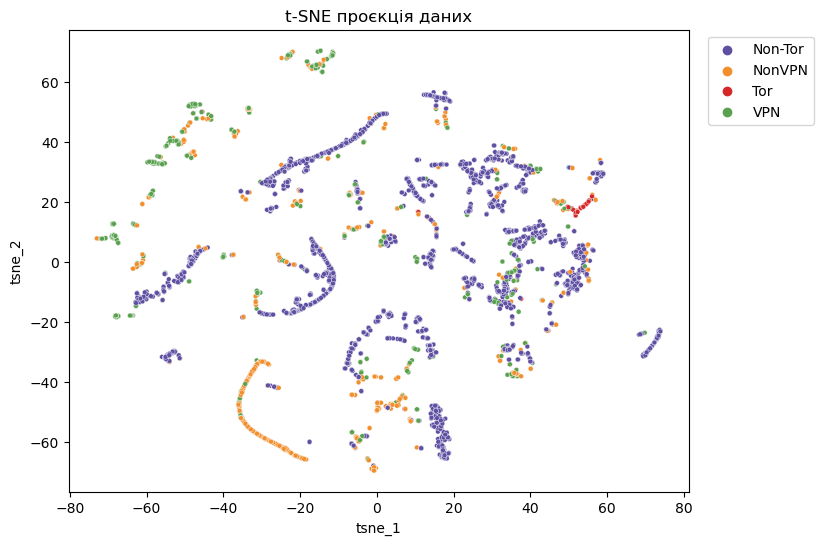

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(scaled_X_train), 4000, replace=False)
X_sub = scaled_X_train[idx]
y_sub = y_train.values[idx]

tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=RANDOM_STATE)
tsne_result = tsne.fit_transform(X_sub)

tsne_df = pd.DataFrame({"tsne_1": tsne_result[:, 0],
                        "tsne_2": tsne_result[:, 1],
                        "Клас": y_sub})

plt.figure(figsize=(8, 6))
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Клас", data=tsne_df, s=12, palette=CLASS_COLORS)
plt.title("t-SNE проєкція даних")
plt.legend(bbox_to_anchor=(1.02, 1), loc=2)
plt.show()

t-SNE зберігає локальну структуру, тому дані розпались на багато дрібних згустків і витягнутих ланцюжків, кожен з яких це група схожих потоків (наприклад, сесії одного застосунку). Більшість згустків однорідні за класом. Tor (червоний) утворює один компактний окремий згусток праворуч унизу, бо його трафік має характерну структуру. NonVPN (помаранчевий) формує власні ланцюжки, зокрема велику дугу ліворуч угорі, а VPN (зелений) окремі групи ліворуч і внизу. Non-Tor найчисленніший і розкиданий по всій площині. Змішування класів помітне переважно в правій центральній частині, де поруч лежать Non-Tor, VPN і NonVPN. Така картина пояснює високу якість Random Forest з Lab 1: класи в основному розділені локально, хоча й не утворюють чотирьох великих хмар. Відстані між згустками в t-SNE не мають прямого змісту, важливо лише, хто з ким сусідить.

## 2. Кластерний аналіз (K-Means)

Кластеризуємо ту саму підвибірку 4000 масштабованих потоків методом K-Means і перевіряємо, чи збігається знайдена структура з реальними класами. Доцільну кількість кластерів визначаємо методом ліктя та за коефіцієнтом силуету.

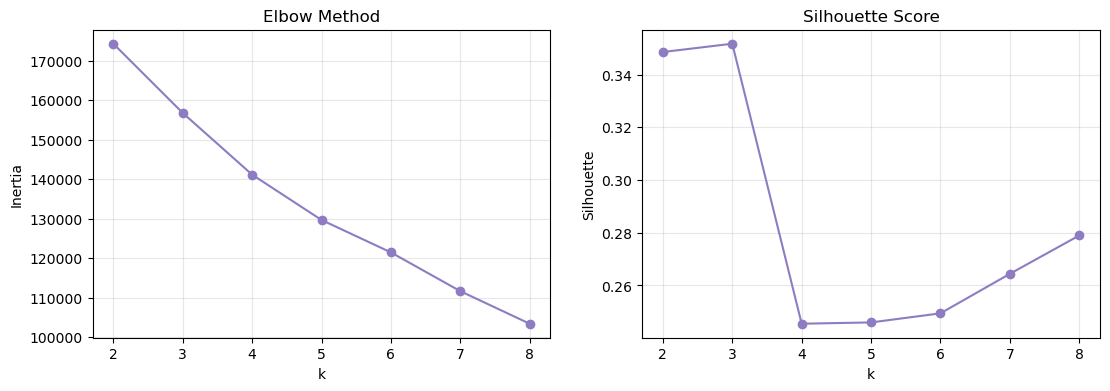

Найкраще k за силуетом: 3


In [7]:
K_range = range(2, 9)
inertias, silhouettes = [], []

X_clust = X_sub 
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clust, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(K_range), inertias, marker="o", color=PURPLE)
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].grid(alpha=0.3)
ax[1].plot(list(K_range), silhouettes, marker="o", color=PURPLE)
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette"); ax[1].grid(alpha=0.3)
plt.show()

best_k = list(K_range)[int(np.argmax(silhouettes))]
print("Найкраще k за силуетом:", best_k)

### Кластеризація з обраним k та візуалізація 

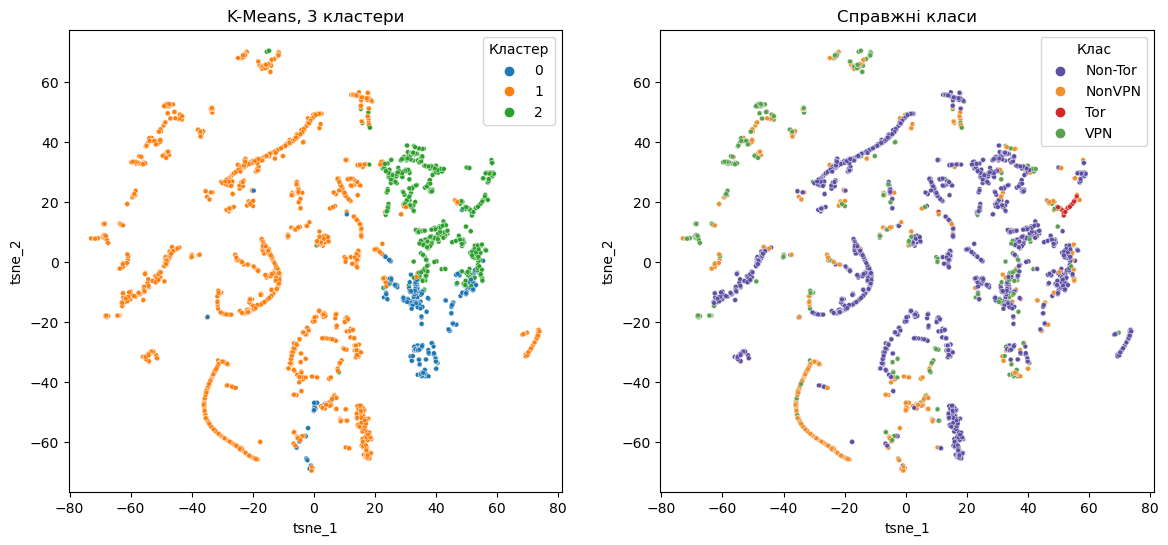

In [8]:
km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
clusters = km.labels_

plot_df = pd.DataFrame({"tsne_1": tsne_result[:, 0],
                        "tsne_2": tsne_result[:, 1],
                        "Кластер": clusters,
                        "Клас": y_sub})

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Кластер", data=plot_df, s=12, palette="tab10", ax=ax[0])
ax[0].set_title(f"K-Means, {best_k} кластери")
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Клас", data=plot_df, s=12, palette=CLASS_COLORS, ax=ax[1])
ax[1].set_title("Справжні класи")
plt.show()

### Порівняння кластерів зі справжніми класами

Таблиця відповідності клас - кластер:
Кластер    0     1    2
Клас                   
Non-Tor  256  1714  554
NonVPN    88   594   55
Tor        2     5   33
VPN       53   579   67

Adjusted Rand Index: -0.04


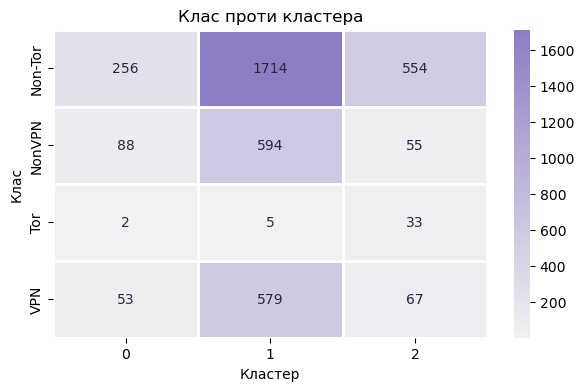

In [9]:
ct = pd.crosstab(plot_df["Клас"], plot_df["Кластер"])
print("Таблиця відповідності клас - кластер:")
print(ct)
print("\nAdjusted Rand Index:", round(adjusted_rand_score(y_sub, clusters), 3))

plt.figure(figsize=(7, 4))
sns.heatmap(ct, cmap=soft, linewidths=1, linecolor="white")
for r in range(ct.shape[0]):
    for c in range(ct.shape[1]):
        plt.text(c + 0.5, r + 0.5, ct.values[r, c], ha="center", va="center", **DARK_TEXT)
plt.title("Клас проти кластера")
plt.show()

### Чим відрізняються кластери

Щоб пояснити, за якою логікою K-Means поділив дані, дивимось на медіани кількох ключових ознак у кожному кластері (у початкових, немасштабованих одиницях).

In [10]:
key_cols = ["Flow Duration", "Total Fwd Packet", "Total Bwd packets",
            "Flow Bytes/s", "Packet Length Mean", "Idle Mean"]
X_sub_raw = X_train.iloc[idx]
summary = X_sub_raw[key_cols].groupby(clusters).median().round(1)
summary["Кількість потоків"] = pd.Series(clusters).value_counts().sort_index().values
summary

,Flow Duration,Total Fwd Packet,Total Bwd packets,Flow Bytes/s,Packet Length Mean,Idle Mean,Кількість потоків
0,90157139.0,4.0,3.0,3.8,38.400002,1.436960e+15,399
1,292842.5,2.0,1.0,105.7,22.000000,0.000000e+00,2892
2,61543372.0,18.0,19.0,608.2,287.299988,1.437770e+15,709


Метод ліктя не дав чіткого згину - інерція спадає плавно, тому орієнтувались на силует, який максимальний при k = 3 (близько 0.35, при k = 2 майже стільки ж), а далі різко падає. Adjusted Rand Index дорівнює -0.04, тобто кластери практично не збігаються з класами, як і попереджає умова, кластер і клас це не одне й те саме. Таблиця відповідності показує, що кожен клас розподілений по всіх кластерах, а кластер 1 містить більшість потоків усіх класів. Медіани ознак пояснюють, за якою логікою K-Means поділив дані. Кластер 1 це короткі потоки (близько 0.3 с) з 1–2 пакетами, кластер 0 це довгі малоактивні з'єднання з кількома пакетами та дуже малою швидкістю, кластер 2 це довгі активні сесії з десятками пакетів і великим середнім розміром пакета. Тобто K-Means згрупував трафік за поведінкою, а не за тим, Tor це, VPN чи звичайне з'єднання. Єдиний помітний збіг це клас Tor, який майже весь (33 з 40) потрапив у кластер 2, адже Tor передає дані великими пакетами фіксованого розміру. Отже, знайдена кластерна структура реальна, але відображає тип активності, а не класи датасету.

## 3. Обробка та класифікація текстових даних

Для класифікації текстів беремо Clickbait Dataset. Він містить 32 000 заголовків англійською: 16 000 клікбейтних із сайтів BuzzFeed, Upworthy, ViralNova та інших і 16 000 звичайних новинних заголовків з WikiNews, The New York Times, The Guardian, The Hindu. 

In [11]:
import re, gzip, urllib.request
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud

BASE = "https://raw.githubusercontent.com/bhargaviparanjape/clickbait/master/dataset/"

def load_headlines(name):
    raw = urllib.request.urlopen(BASE + name).read()
    lines = gzip.decompress(raw).decode("utf8").splitlines()
    return [l.strip() for l in lines if l.strip()]

clickbait = load_headlines("clickbait_data.gz")
news = load_headlines("non_clickbait_data.gz")
cb = pd.DataFrame({"headline": clickbait + news,
                   "label": ["clickbait"] * len(clickbait) + ["news"] * len(news)})
print("Розмір:", cb.shape)
print(cb["label"].value_counts())
cb.sample(6, random_state=RANDOM_STATE)

Розмір: (32000, 2)
label
news         16001
clickbait    15999
Name: count, dtype: int64


,headline,label
23100,Filipino activist arrested for disrupting Mani...,news
17362,"International Board fixes soccer field size, h...",news
8993,24 Rules For Women On A First Date With A Man,clickbait
19566,Political fallout from the sacking of Professo...,news
3798,"Which ""Clueless"" Character Are You Based On Yo...",clickbait
12573,24 Hauntingly Beautiful Tattoos Featuring No F...,clickbait


Класи збалансовані, приблизно по 16 000 заголовків, тому accuracy тут чесна метрика, але, як і раніше, дивимось також на macro F1 і ділимо вибірку зі stratify. Заголовки короткі: у середньому 9 слів.

### Передобробка текстів

Переводимо текст у нижній регістр, прибираємо пунктуацію й цифри, видаляємо англійські стоп-слова та слова коротші за 3 літери.

In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(tokens)

cb["clean"] = cb["headline"].apply(clean_text)
cb[["headline", "clean"]].iloc[[0, 1, 16000, 16001]]

,headline,clean
0,Should I Get Bings,bings
1,Which TV Female Friend Group Do You Belong In,female friend group belong
16000,"In Hollywood, the Easy-Money Generation Toughe...",hollywood easy money generation toughens
16001,1700 runners still unaccounted for in UK's Lak...,runners unaccounted lake district following flood


### WordCloud для кожного класу

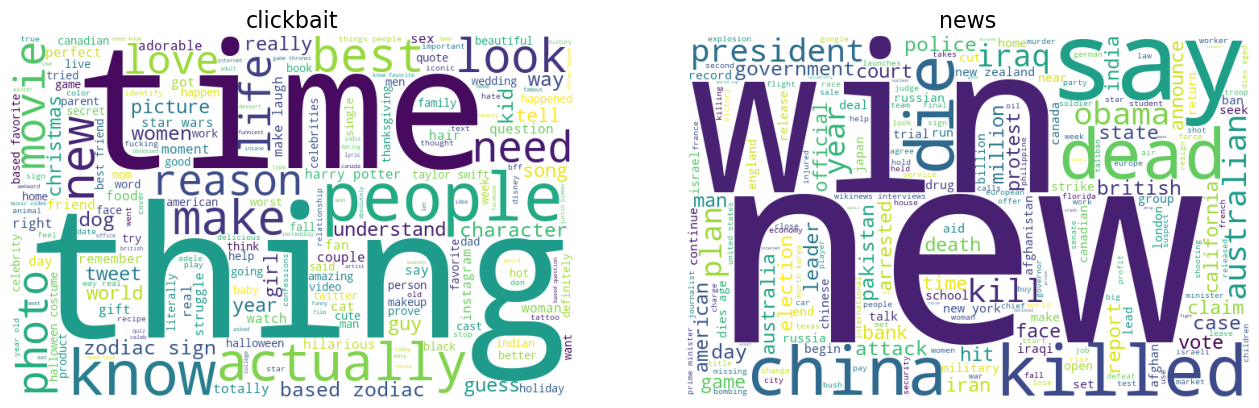

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cls in zip(axes, ["clickbait", "news"]):
    text = " ".join(cb.loc[cb["label"] == cls, "clean"])
    wc = WordCloud(width=700, height=450, background_color="white",
                   colormap="viridis", random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc)
    ax.axis("off")
    ax.set_title(cls, fontsize=16)
plt.show()

Хмари слів дуже різні. У clickbait переважають thing, time, people, know, actually, best, need, look, make, life, reason, photo, тобто загальні, емоційні слова й обіцянки («things you need to know», «best photos», «actually happened»), які інтригують, але нічого конкретного не повідомляють. Також помітні теми розваг: movie, christmas, zodiac sign, taylor swift, harry potter. У news домінують new, win, say, killed, dead, china, president, obama, police, election, government, тобто конкретні події, країни, особи й дієслова дій («says», «wins», «killed»). Отже, клікбейт описує емоцію і загадку, а новина конкретний факт, і за лексикою класи добре розділяються.

### Векторизація TF-IDF та класифікація

Ділимо дані на train/test, векторизуємо тексти через TfidfVectorizer, який зважує слово за частотою в заголовку та рідкістю в усій колекції. Беремо окремі слова та біграми  і навчаємо логістичну регресію.

In [14]:
Xtr_txt, Xte_txt, ytr_txt, yte_txt = train_test_split(
    cb["clean"], cb["label"], test_size=0.20, stratify=cb["label"], random_state=RANDOM_STATE)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
Xtr = tfidf.fit_transform(Xtr_txt)
Xte = tfidf.transform(Xte_txt)
print("Розмір словника:", len(tfidf.vocabulary_))

clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
clf.fit(Xtr, ytr_txt)
pred = clf.predict(Xte)

print("Accuracy:", round(accuracy_score(yte_txt, pred), 4))
print("Macro F1:", round(f1_score(yte_txt, pred, average="macro"), 4))
print(classification_report(yte_txt, pred, digits=3))

Розмір словника: 19656
Accuracy: 0.9534
Macro F1: 0.9534
              precision    recall  f1-score   support

   clickbait      0.968     0.938     0.953      3200
        news      0.940     0.969     0.954      3200

    accuracy                          0.953      6400
   macro avg      0.954     0.953     0.953      6400
weighted avg      0.954     0.953     0.953      6400



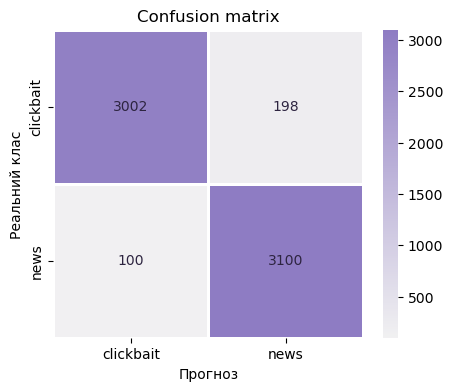

In [15]:
cm = confusion_matrix(yte_txt, pred, labels=["clickbait", "news"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, cmap=soft, linewidths=1, linecolor="white",
            xticklabels=["clickbait", "news"], yticklabels=["clickbait", "news"])
for r in range(2):
    for c in range(2):
        plt.text(c + 0.5, r + 0.5, cm[r, c], ha="center", va="center", **DARK_TEXT)
plt.xlabel("Прогноз"); plt.ylabel("Реальний клас")
plt.title("Confusion matrix")
plt.show()

### Найважливіші слова для моделі

In [16]:
coef = pd.Series(clf.coef_[0], index=tfidf.get_feature_names_out()) 
print("Найсильніші ознаки clickbait:", coef.sort_values().head(10).index.tolist())
print("Найсильніші ознаки news:", coef.sort_values(ascending=False).head(10).index.tolist())

Найсильніші ознаки clickbait: ['things', 'people', 'actually', 'know', 'make', 'best', 'like', 'times', 'character', 'guess']
Найсильніші ознаки news: ['dies', 'wins', 'china', 'obama', 'kills', 'president', 'iraq', 'australian', 'court', 'police']


У клікбейті багато займенників і службових слів (you, your, this, these, will), які стандартний список стоп-слів видаляє. Перевіримо, як зміниться якість, якщо їх залишити, а прибрати лише пунктуацію й цифри.

In [17]:
def clean_keep_stop(text):
    return " ".join(re.sub(r"[^a-z\s]", " ", text.lower()).split())

cb["clean_full"] = cb["headline"].apply(clean_keep_stop)
Xtr_f, Xte_f = cb.loc[Xtr_txt.index, "clean_full"], cb.loc[Xte_txt.index, "clean_full"]
tfidf_f = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
clf_f = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(tfidf_f.fit_transform(Xtr_f), ytr_txt)
pred_f = clf_f.predict(tfidf_f.transform(Xte_f))
print("Зі стоп-словами: accuracy =", round(accuracy_score(yte_txt, pred_f), 4),
      "| macro F1 =", round(f1_score(yte_txt, pred_f, average="macro"), 4))
coef_f = pd.Series(clf_f.coef_[0], index=tfidf_f.get_feature_names_out())
print("Найсильніші ознаки clickbait:", coef_f.sort_values().head(10).index.tolist())

Зі стоп-словами: accuracy = 0.9642 | macro F1 = 0.9642
Найсильніші ознаки clickbait: ['you', 'this', 'your', 'that', 'the', 'things', 'people', 'who', 'times', 'these']


Логістична регресія на TF-IDF досягла accuracy 0.953 і macro F1 0.953, обидва класи розпізнаються майже однаково (F1 0.953 для clickbait і 0.954 для news). За матрицею помилок модель пропустила 198 клікбейтних заголовків із 3200 (назвала їх новинами) і помилково позначила як клікбейт 100 новин із 3200. Найсильніші ознаки клікбейту things, actually, people, know, best, guess, character, а новин dies, wins, china, obama, president, kills, police, що збігається з хмарами слів. Окремий експеримент показав, що для цієї задачі видаляти стоп-слова не варто: без видалення accuracy і macro F1 зросли до 0.964, а найсильнішими ознаками клікбейту стали саме you, this, your, that, these. Звернення до читача («you», «your») і вказівні слова («this», «these») це головні маркери клікбейту, тож стандартна передобробка прибирає частину корисного сигналу. Класи збалансовані, тому тут accuracy і macro F1 практично збігаються.

## Висновок

У роботі розглянуто три базові задачі навчання без учителя та обробки текстів. PCA стиснув 64 ознаки до 26 зі збереженням 95 % дисперсії, але для Random Forest це знизило macro F1 з 0.940 до 0.892 і в кілька разів збільшило час навчання. t-SNE показав, що дані складаються з багатьох однорідних за класом згустків, Tor утворює окрему групу, а змішування класів трапляється лише в частині простору. K-Means з k = 3 згрупував потоки за типом активності, а не за класами (ARI -0.04), що підтверджує різницю між кластером і класом. Для текстів зв'язка передобробка, WordCloud, TF-IDF і логістична регресія відрізняє клікбейтні заголовки від новинних з macro F1 0.953, а без видалення стоп-слів 0.964, бо займенники you, your, this є ключовими ознаками клікбейту.